In [2]:
%load_ext autoreload
%autoreload 2

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iml.dungeon import Dungeon
from iml.agent import DungeonAgent
from iml.visualization import DungeonVisualization
from iml.dungeon_maker import make_treasure_room, make_underground_maze, make_underground_maze_with_meat

**Group members:** 
- Manuel Sousa Lourenço
- Rafael Rocha
- Valentin
- Bastian

## Part 1: Gridworld Environment

### 1.1 A drunken knight in a treasure room
### (a)
> Implement a stochastic policy where you select actions uniformly at random.

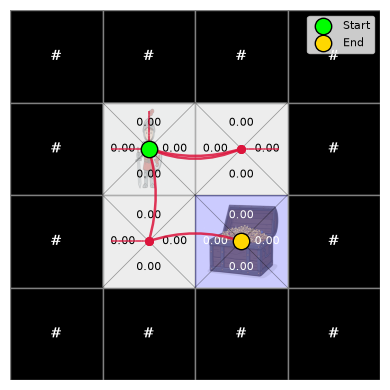

In [26]:
def my_reward_11(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_11(state, q_value):
	# <implement your action here>
	# return ... (int)
    return np.random.choice(4)

def my_Q_update_11(agent, state, action, reward, next_state, dungeon):
    return None # use None for now

treasure_room = make_treasure_room()
vis_11 = DungeonVisualization(treasure_room)

drunken_knight = DungeonAgent(n_states=treasure_room.n_states, 
                             choose_action=my_action_11,
                             reward_func=my_reward_11,
                             update_q_values=my_Q_update_11)

# Run the agent for 1 episode & collect states, actions, rewards
states, actions, rewards = drunken_knight.run_episode(treasure_room, nstep=10, gamma=1.0)

# Show the map, Q-values, and path.
vis_11.show(states, actions, drunken_knight.q_values)

### (b)
> Observe how you move and draw a Markov decision process (MDP) diagram for all four non-wall states.

*(Insert your MDP diagram photo/figure here)*

The treasure room contains four non-wall states: \(s_0, s_1, s_2\) and \(s_3\), where:

- \(s_0\): Starting position = s
- \(s_1\): Top-right position = A
- \(s_2\): Bottom-left position = B
- \(s_3\): Goal position = e

The agent has four possible actions:

- 0: Down
- 1: Up
- 2: Right
- 3: Left

The stochastic policy selects each action with probability \(1/4\).

When the agent attempts to move into a wall, it remains in the same state, resulting in a self-loop.

The following diagram illustrates all possible state transitions and actions.

![MDP Diagram](homework_2_1.1_b.png)

### (c)
> Compute the theoretical probability distribution over a 2-step horizon analytically (without writing code) when you use the stochastic policy you implemented.


The stochastic policy selects each of the four possible actions uniformly at random. Therefore, each action has a probability of:

$$
P(a \mid s) = \frac{1}{4} = 0.25
$$

The treasure room contains four accessible states:

- $s$: Starting position.
- $A$: State to the right of the starting position.
- $B$: State below the starting position.
- $e$: Goal state.

When the agent tries to move into a wall, it remains in the same state. Therefore, the probability of staying in the starting state is $0.5$, since two of the four possible actions lead to a wall.

**Step 1: Probability distribution after one step**

Starting from $s$, the possible transitions are:

$$
P(s_1=s)=0.5
$$

$$
P(s_1=A)=0.25
$$

$$
P(s_1=B)=0.25
$$

**Step 2: Probability distribution after two steps**

To calculate the probability of reaching each state after two steps, we consider all possible paths leading to that state.

We multiply the probabilities along each path and add the probabilities of different paths that reach the same final state.

The general formula is:

$$
P(s_2 \mid s_0) =
\sum_{s_1} P(s_1 \mid s_0)P(s_2 \mid s_1)
$$

**1. Probability of ending in the starting state ($s$)**

There are three possible paths:

- $s \rightarrow s \rightarrow s$
- $s \rightarrow A \rightarrow s$
- $s \rightarrow B \rightarrow s$

Therefore:

$$
\begin{aligned}
P(s_2=s) &= (0.5 \times 0.5) \\
&\quad + (0.25 \times 0.25) \\
&\quad + (0.25 \times 0.25) \\
&= 0.25+0.0625+0.0625 \\
&= \boxed{0.375}
\end{aligned}
$$

**2. Probability of ending in state $A$**

There are two possible paths:

- $s \rightarrow s \rightarrow A$
- $s \rightarrow A \rightarrow A$

Therefore:

$$
\begin{aligned}
P(s_2=A) &= (0.5 \times 0.25) \\
&\quad + (0.25 \times 0.5) \\
&= \boxed{0.25}
\end{aligned}
$$

**3. Probability of ending in state $B$**

There are two possible paths:

- $s \rightarrow s \rightarrow B$
- $s \rightarrow B \rightarrow B$

Therefore:

$$
\begin{aligned}
P(s_2=B) &= (0.5 \times 0.25) \\
&\quad + (0.25 \times 0.5) \\
&= \boxed{0.25}
\end{aligned}
$$

**4. Probability of reaching the goal ($e$)**

There are two possible paths:

- $s \rightarrow A \rightarrow e$
- $s \rightarrow B \rightarrow e$

Therefore:

$$
\begin{aligned}
P(s_2=e) &= (0.25 \times 0.25) \\
&\quad + (0.25 \times 0.25) \\
&= \boxed{0.125}
\end{aligned}
$$

**Final probability distribution**

| State | Probability at $t=2$ |
|---|---:|
| Starting state ($s$) | 0.375 (37.5%) |
| State $A$ | 0.250 (25%) |
| State $B$ | 0.250 (25%) |
| Goal ($e$) | 0.125 (12.5%) |
| **Total** | **1.000 (100%)** |

Finally, we verify that the probabilities sum to 1:

$$
0.375+0.25+0.25+0.125=1
$$

This confirms that the calculated values form a valid probability distribution.


### (d)
> If you implement Q-learning with an episode length of 1 (`nstep = 1`) under current setup, will you manage to perform better? Why or why not? Explain your reasoning.


With `nstep = 1`, the agent can only perform one action per episode. Since the goal requires more than one movement from the starting state, the agent cannot reach the treasure within a single episode.

Consequently, the agent always receives a reward of 0, because the reward function only returns 1 when the goal state is reached. Therefore, the agent does not receive positive feedback to learn which actions lead to the goal.

Furthermore, since the stochastic policy selects actions uniformly at random, the agent does not prefer actions based on their Q-values. As a result, the agent cannot effectively learn how to reach the goal under this configuration.

### (e)
> For a dungeon of width $N$ and height $M$, what is the minimum number of steps required to reach the goal from the starting position? Why? 


For a dungeon with width \(N\) and height \(M\), assuming the starting position and the goal are in opposite corners and there are no obstacles blocking the shortest path, the minimum number of steps is:

$$
d_{\min} = (N-1) + (M-1)
$$

Therefore:

$$
d_{\min} = N + M - 2
$$

The agent needs \(N-1\) horizontal steps and \(M-1\) vertical steps to reach the goal.

In the specific treasure room used in this exercise, the agent needs only 2 steps: one step to the right and one step down (or vice versa).


This also explains the result in question 1.1 (d): with `nstep = 1`, the agent cannot reach the goal because it needs at least 2 movements, while the episode ends after only 1 step.

---
### 1.2 A tricky knight in an underground maze

### (a)
> (a) Using your stochastic policy $\pi$, implement the Q-learning update with a discount factor ($\gamma = 1$) and a maximum episode length of 30 steps ($n_{\text{step}} = 30$). Run consecutive episodes without resetting the Q-table. Explain your observations on how the Q-values change relative to the goal and starting locations.

Number of states: 35
Q-table dimension: (4, 35)


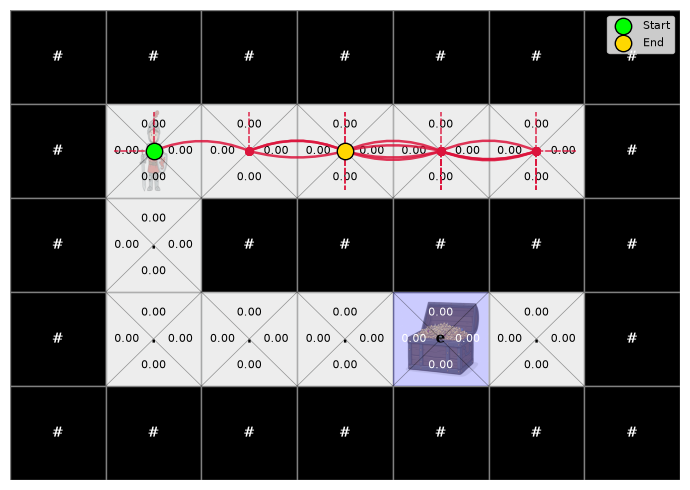

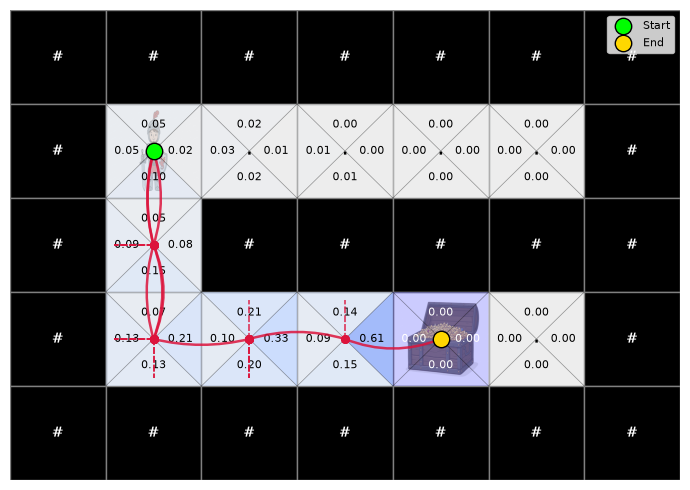

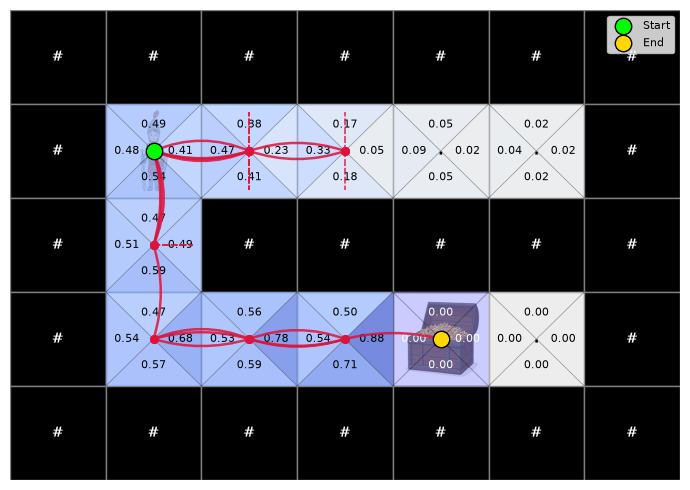

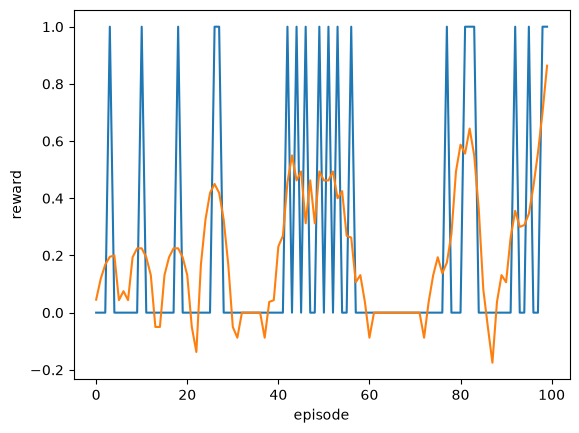

In [62]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values):
    return np.random.choice(4) 

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
	# <implement your Q update here>
	# Hint: lecture 9, page 18 <20/29>
	# return ... (float)
    alpha = 0.1
    gamma = 1.0

    old_q = agent.q_values[action, state]

    max_next_q = np.max(agent.q_values[:, next_state])

    # Formula
    new_q = old_q + alpha * (
        reward + gamma * max_next_q - old_q
    )

    agent.q_values[action, state] = new_q

    return new_q

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

training_reward = []
# program your knight here
# compute episodic reward
# append "training_reward"
print("Number of states:", underground_maze.n_states)
print("Q-table dimension:", tricky_knight.q_values.shape)

for episode in range(100):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=1.0)

    training_reward.append(np.sum(rewards))

    if episode in [0, 49, 99]:
        vis_12.show(states, actions, tricky_knight.q_values)

# plot "training_reward"
vis_12.plot_training_reward(training_reward)

### Explanation of Q-value evolution

Initially, all Q-values are zero. When the agent reaches the goal, it receives a reward of 1, causing the Q-values of actions leading directly to the goal to increase.

Over time, these positive values propagate backwards to states further away from the goal, including states closer to the starting position.

Since the agent follows a uniformly random policy, some states and actions may not be visited frequently. Therefore, their Q-values may remain close to zero. The Q-values generally increase with training, but the learning process is irregular due to the random action selection.

### (b)
> By varying the discount factor $\gamma$, do you observe any differences? Summarize how the discount rate affects the results and explain why it is necessary.


### (c)
> Implement an $\epsilon$-greedy policy for your agent by varying $\epsilon$. Plot the sum of discounted rewards per episode over 100 training runs and explain your observations.

### (d)
> Is a single training run sufficient to evaluate and compare an agent’s performance across different hyperparameter settings? Specifically: (i) Will an agent reach the goal on every evaluation episode? Explain why or why not. (ii) Under what specific conditions would RL training and evaluation results be strictly deterministic and reproducible? And (iii) Given these factors, how should an RL agent's performance be properly evaluated and compared, both when those deterministic conditions are met and when they are not?

### (e)
> Recreate the maze using `make_underground_maze_with_meat()`, update the reward function, set $\epsilon = 0.9$, $n_{\text{step}} = 50$, and $\gamma = 0.95$, and run the agent for 100 to 200 training runs. Explain your observations regarding your strategy (Q-values) and behavior.

In [5]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    if dungeon.tiles[next_state] == "+":
        return 0.5
    return 0.0

def my_action_12(state, q_values):
	# <implement your action here>
	# return ... (int)

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
	# <implement your Q update here>
	# Hint: lecture 9, page 18 <20/29>
	# return ... (float)

underground_maze = make_underground_maze_with_meat(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

training_reward = []
# program your knight here
# compute episodic reward
# append "training_reward"

# plot "training_reward"
vis_12.plot_training_reward(training_reward)

IndentationError: expected an indented block after function definition on line 8 (2625343998.py, line 12)

> (f) Compare the state values $V(s)$ when you go directly to the treasure (e), collects free meat as you observed (+), or do both. Explain your results mathematically.


> (g) How might you modify the reward function or environment design to prevent this *reward hacking*? Propose and explain a solution. (Bonus)

## Part 2: Bayesian Decision-Making in Multi-Armed Bandits

### 2.1 Bayesian Estimation of Arm Rewards

### (a)
> Starting from Bayes' theorem and the Bernoulli likelihood, derive the posterior distribution $p(\theta \mid D)$ and identify its updated parameters. Hence, show that the Beta distribution is a conjugate prior to the Bernoulli likelihood. 

### (b)
> Suppose the prior is $(\beta(2,2))$. After ten pulls, the arm produces seven successes and three failures. Compute the posterior distribution and posterior mean. Show that, in general, the posterior mean can be expressed as a weighted average of the prior mean and the empirical success rate. Interpret the weights and explain how they change as the number of observations increases

### 2.2 Learning with Thompson Samplin

### (a)
> Implement a five-armed Bernoulli bandit environment that generates binary rewards using the given success probabilities. Then implement a Thompson sampling agent that maintains the posterior parameters for each arm, selects actions using posterior sampling, and updates the corresponding posterior after receiving each reward. 

### (b)
> Using the results from part (a), plot the evolution of the posterior mean estimates for all five arms as a function of time; visualize the posterior distributions; discuss how the posterior means and distributions evolve; and explain why some arms become more certain about their estimated success probabilities than others.

### 2.3 Experimental Evaluation and Exploration

### (a)
> Perform 100 independent trials of Thompson sampling, each consisting of 2,000 decisions. Initialize a new agent with the same priors at the beginning of every trial.

### (b)
> Derive the agent's expected reward per decision and its expected instantaneous pseudo-regret. Hence, derive the expected cumulative pseudo-regret $\mathbb{E}[\mathcal{R}_T]$. How does it grow with $T$, assuming $\epsilon$ remains fixed and the greedy choice remains optimal? (Bonus)

### (c)
> Compare $\epsilon$-greedy exploration with Thompson sampling. Explain why Thompson sampling may select an arm with a lower posterior mean and how its exploration behavior changes as more observations accumulate.